In [1]:
!pip install ucimlrepo

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


UCI Repo Import including all derived features

In [3]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# fetch dataset
phiusiil_phishing_url_website = fetch_ucirepo(id=967)

# data (as pandas dataframes)
X = phiusiil_phishing_url_website.data.features
y = phiusiil_phishing_url_website.data.targets

data = pd.concat([X, y], axis=1)

# metadata
print(phiusiil_phishing_url_website.metadata)

# variable information
print(phiusiil_phishing_url_website.variables)

{'uci_id': 967, 'name': 'PhiUSIIL Phishing URL (Website)', 'repository_url': 'https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/967/data.csv', 'abstract': 'PhiUSIIL Phishing URL Dataset is a substantial dataset comprising 134,850 legitimate and 100,945 phishing URLs. Most of the URLs we analyzed, while constructing the dataset, are the latest URLs. Features are extracted from the source code of the webpage and URL. Features such as CharContinuationRate, URLTitleMatchScore, URLCharProb, and TLDLegitimateProb are derived from existing features.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 235795, 'num_features': 54, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['label'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2024, 'last_updated': 'Sun May 12 

In [4]:
# dataset uses "label" = 1 if legitimate and "label" = 0 if phishing site.
# changing to "label" = 0 if legitimate and "label" = 1 if phishing site.

data['label'] = data['label'].map({0: 1, 1: 0})

"label" = 0 is a legitimate website. "label" = 1 is a phishing site.

In [5]:
# pre-processing steps

# scores calculated after downloading webpage HTML
webpage_features_to_drop = [
    'LineOfCode', 'LargestLineLength', 'HasTitle',
    'HasFavicon', 'Robots', 'IsResponsive',
    'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup',
    'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
    'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
    'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
    'NoOfEmptyRef', 'NoOfExternalRef'
]

# derived features from URL
derived_features_to_drop = [
    'CharContinuationRate',
    'URLSimilarityIndex',
    'URLTitleMatchScore',
    'URLCharProb',
    'TLDLegitimateProb'
]

# non-numeric features
columns_to_drop_num = ['label', 'URL', 'Domain', 'TLD', 'Title']

# non_numeric features + webpage scores
columns_to_drop_num.extend(webpage_features_to_drop)
columns_to_drop_num.extend(derived_features_to_drop)

PhishOFE Dataset Mounting and Pre-processing

In [6]:
phishofe_path = '/content/drive/MyDrive/PhishOFE_ds.csv'
phishofe_data = pd.read_csv(phishofe_path)

print("PhishOFE Dataset Head:")
display(phishofe_data.head())

X_phishofe = phishofe_data['URL']
y_phishofe = phishofe_data['label']

print(f"Total URLs in PhishOFE dataset: {len(X_phishofe)}")

PhishOFE Dataset Head:


,URL,IsHTTPS,IsDomainIP,TLD,URLLength,NoOfSubDomain,NoOfDots,NoOfObfuscatedChar,NoOfEqual,NoOfQmark,...,HasKeywordPay,HasKeywordCrypto,NoOfPopup,NoOfiFrame,NoOfImage,NoOfJS,NoOfCSS,NoOfURLRedirect,NoOfHyperlink,label
0,https://www.fow.kr,1,0,kr,18,1,2,0,0,0,...,0,0,0,0,81,16,2,2,57,0
1,https://www.visa.com.ar,1,0,ar,23,2,3,0,0,0,...,1,0,0,0,11,31,10,0,11,0
2,https://www.inflibnet.ac.in,1,0,in,27,2,3,0,0,0,...,0,0,0,1,42,26,10,0,229,0
3,https://www.lyrsense.com,1,0,com,24,1,2,0,0,0,...,0,0,0,0,106,14,1,1,331,0
4,https://www.61saat.com,1,0,com,22,1,2,0,0,0,...,0,0,1,1,79,46,4,0,275,0


Total URLs in PhishOFE dataset: 101063


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [8]:
# plot confusion matrix function
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrix(model, X_test, y_test, title="Confusion Matrix"):
    """
    Plots a confusion matrix for a given model and test data.
    """
    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=['Legitimate website', 'Phishing website'],
        cmap='Blues',
        ax=ax
    )

    # Row 0 (Actual: Legit)    -> [Predicted 0 (TN), Predicted 1 (FP)]
    # Row 1 (Actual: Phishing) -> [Predicted 0 (FN), Predicted 1 (TP)]
    custom_labels = [['(TN)', '(FP)'],
                     ['(FN)', '(TP)']]

    for i in range(2):
        for j in range(2):
            original_text = disp.text_[i, j].get_text()
            disp.text_[i, j].set_text(f"{original_text}\n{custom_labels[i][j]}")

    ax.set_title(title)
    plt.tight_layout()
    plt.show()

In [9]:
# metrics function

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model, X_test, y_test):
    """
    Predictions, prints metrics, and returns them for data tables.
    """
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("-" * 30)

In [10]:
# feature importance bar chart

import seaborn as sns

def plot_top_features(pipeline, X_train, model_step_name='rf', top_n=15, title="Feature Importance"):
    """
    Extracts and plots the top N important features from a Random Forest pipeline.
    """
    # get model from pipeline
    rf_model = pipeline.named_steps[model_step_name]

    # get importances and feature names
    importances = rf_model.feature_importances_
    feature_names = X_train.columns

    # create DataFrame for easy sorting
    feature_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })

    # sort and select top N
    feature_df = feature_df.sort_values(by='Importance', ascending=False).head(top_n)

    # plot
    plt.figure(figsize=(10, 8))
    sns.barplot(x='Importance', y='Feature', hue='Feature', data=feature_df, palette='viridis', legend=False)
    plt.title(title, fontsize=16)
    plt.xlabel('Gini Importance Score', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.tight_layout()
    plt.show()

In [11]:
# kfold-cross verification

import numpy as np
import copy
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def run_kfold_cv(X, y, pipeline, n_splits=5):
    """
    Performs K-Fold CV on Pandas Series or Numpy arrays and tracks
    Accuracy, Precision, Recall, and F1-Score.

    Args:
        X: Feature data (e.g., X_train_url)
        y: Target labels (e.g., y_train_url)
        pipeline: The sklearn pipeline to train (e.g., pipe_char)
        n_splits: Number of folds
    """
    if hasattr(X, 'values'):
        X = X.values
    if hasattr(y, 'values'):
        y = y.values

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    best_score = -np.inf
    best_model = None

    # Lists to store the metrics for each fold
    accuracies = []
    precisions = []
    recalls = []
    f1_scores = []

    print(f"Starting {n_splits}-Fold Cross Validation...")

    for k, (idx_train, idx_val) in enumerate(kf.split(X)):

        # split data using the positional indices
        X_train_k = X[idx_train]
        y_train_k = y[idx_train]
        X_val_k = X[idx_val]
        y_val_k = y[idx_val]

        # clone pipeline
        current_pipe = copy.deepcopy(pipeline)

        # fit
        current_pipe.fit(X_train_k, y_train_k)

        # predict to calculate metrics
        y_pred_k = current_pipe.predict(X_val_k)

        # score metrics
        acc = accuracy_score(y_val_k, y_pred_k)
        prec = precision_score(y_val_k, y_pred_k, zero_division=0)
        rec = recall_score(y_val_k, y_pred_k, zero_division=0)
        f1 = f1_score(y_val_k, y_pred_k, zero_division=0)

        # append to lists
        accuracies.append(acc)
        precisions.append(prec)
        recalls.append(rec)
        f1_scores.append(f1)

        print(f"Fold {k+1}: Acc = {acc:.5f} | Prec = {prec:.5f} | Rec = {rec:.5f} | F1 = {f1:.5f}")

        # track best model (based on accuracy)
        if acc > best_score:
            best_score = acc
            best_model = copy.deepcopy(current_pipe)

    print("-" * 50)
    print(f"Average Accuracy:  {np.mean(accuracies):.5f}")
    print(f"Average Precision: {np.mean(precisions):.5f}")
    print(f"Average Recall:    {np.mean(recalls):.5f}")
    print(f"Average F1-Score:  {np.mean(f1_scores):.5f}")
    print(f"Best Validation Accuracy: {best_score:.5f}")

    return best_model, accuracies

In [12]:
from scipy.stats import wilcoxon

def compare_models_wilcoxon(scores_a, scores_b, model_a_name="Model A", model_b_name="Model B", alpha=0.05):
    """
    Performs a Wilcoxon signed-rank test on paired cross-validation scores.
    """
    print(f"\n--- Wilcoxon Signed-Rank Test: {model_a_name} vs {model_b_name} ---")

    stat, p_value = wilcoxon(scores_a, scores_b, alternative='less')
    print(f"Wilcoxon Statistic: {stat:.4f}")
    print(f"P-value: {p_value:.5f}")

    if p_value < alpha:
        print("Result: Statistically SIGNIFICANT difference (Reject H0).")
        print(f"Conclusion: {model_b_name} genuinely performs differently than {model_a_name}.")
    else:
        print("Result: NO statistically significant difference (Fail to reject H0).")
        print("Conclusion: The performance difference is likely due to random chance.")

Numerical modelling without webpage scores

In [13]:
y = data['label']
X = data.drop(columns=columns_to_drop_num)

# test size = 0.2
test_size_requested = 0.2
X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(X, y, test_size=test_size_requested, random_state=35)

Logistic regression without webpage scores

In [14]:
# logistic regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# max_iter=2000
lr = LogisticRegression(max_iter=2000)

lr_pipe = Pipeline([('scaler', StandardScaler()), ('lr', lr)])
lr_pipe.fit(X_train_num, y_train_num)
y_pred_lr = lr_pipe.predict(X_test_num)

print("accuracy score = ", lr_pipe.score(X_test_num, y_test_num))

evaluate_model(lr_pipe, X_test_num, y_test_num)

accuracy score =  0.9963315591933671
Accuracy:  0.9963
Precision: 0.9993
Recall:    0.9921
F1 Score:  0.9957
------------------------------


In [15]:
run_kfold_cv(X_train_num, y_train_num, lr_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99613 | Prec = 0.99919 | Rec = 0.99179 | F1 = 0.99548
Fold 2: Acc = 0.99589 | Prec = 0.99912 | Rec = 0.99126 | F1 = 0.99517
Fold 3: Acc = 0.99613 | Prec = 0.99931 | Rec = 0.99165 | F1 = 0.99547
Fold 4: Acc = 0.99547 | Prec = 0.99900 | Rec = 0.99039 | F1 = 0.99468
Fold 5: Acc = 0.99650 | Prec = 0.99956 | Rec = 0.99228 | F1 = 0.99591
--------------------------------------------------
Average Accuracy:  0.99602
Average Precision: 0.99924
Average Recall:    0.99147
Average F1-Score:  0.99534
Best Validation Accuracy: 0.99650


(Pipeline(steps=[('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=2000))]),
 [0.9961301950805768,
  0.9958915365653246,
  0.9961300925066928,
  0.9954674371140032,
  0.996501179526599])

Random Forest Classification (n=100) without webpage scores

In [16]:
# random forest classification

# n=100
rf = RandomForestClassifier(n_estimators=100)

rf_pipe = Pipeline([('rf', rf)])
rf_pipe.fit(X_train_num, y_train_num)
y_pred_rf = rf_pipe.predict(X_test_num)

accuracy = accuracy_score(y_test_num, y_pred_rf)

print("accuracy score = ", accuracy)

evaluate_model(rf_pipe, X_test_num, y_test_num)

accuracy score =  0.9976250556627579
Accuracy:  0.9976
Precision: 0.9993
Recall:    0.9951
F1 Score:  0.9972
------------------------------


In [17]:
best_rf_url, acc_rf_url = run_kfold_cv(X_train_num, y_train_num, rf_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99764 | Prec = 0.99907 | Rec = 0.99543 | F1 = 0.99725
Fold 2: Acc = 0.99700 | Prec = 0.99882 | Rec = 0.99417 | F1 = 0.99649
Fold 3: Acc = 0.99764 | Prec = 0.99913 | Rec = 0.99536 | F1 = 0.99724
Fold 4: Acc = 0.99700 | Prec = 0.99900 | Rec = 0.99399 | F1 = 0.99649
Fold 5: Acc = 0.99753 | Prec = 0.99919 | Rec = 0.99506 | F1 = 0.99712
--------------------------------------------------
Average Accuracy:  0.99737
Average Precision: 0.99904
Average Recall:    0.99480
Average F1-Score:  0.99692
Best Validation Accuracy: 0.99764


XGBoost without webpage scores

In [18]:
# XGBoost

from xgboost import XGBClassifier


# n=100, max depth=6
xgb = XGBClassifier(n_estimators=100, max_depth=6)

xgb_pipe = Pipeline([('xgb', xgb)])
xgb_pipe.fit(X_train_num, y_train_num)
y_pred_xgb = xgb_pipe.predict(X_test_num)

accuracy = accuracy_score(y_test_num, y_pred_xgb)

print("accuracy score = ", accuracy)

evaluate_model(xgb_pipe, X_test_num, y_test_num)

accuracy score =  0.9979855382853751
Accuracy:  0.9980
Precision: 0.9998
Recall:    0.9955
F1 Score:  0.9976
------------------------------


In [19]:
run_kfold_cv(X_train_num, y_train_num, xgb_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99777 | Prec = 0.99944 | Rec = 0.99537 | F1 = 0.99740
Fold 2: Acc = 0.99743 | Prec = 0.99931 | Rec = 0.99467 | F1 = 0.99699
Fold 3: Acc = 0.99793 | Prec = 0.99969 | Rec = 0.99549 | F1 = 0.99758
Fold 4: Acc = 0.99722 | Prec = 0.99950 | Rec = 0.99399 | F1 = 0.99674
Fold 5: Acc = 0.99788 | Prec = 0.99975 | Rec = 0.99531 | F1 = 0.99753
--------------------------------------------------
Average Accuracy:  0.99765
Average Precision: 0.99954
Average Recall:    0.99496
Average F1-Score:  0.99725
Best Validation Accuracy: 0.99793


(Pipeline(steps=[('xgb',
                  XGBClassifier(base_score=None, booster=None, callbacks=None,
                                colsample_bylevel=None, colsample_bynode=None,
                                colsample_bytree=None, device=None,
                                early_stopping_rounds=None,
                                enable_categorical=False, eval_metric=None,
                                feature_types=None, feature_weights=None,
                                gamma=None, grow_policy=None,
                                importance_type=None,
                                interaction_constraints=None, learning_rate=None,
                                max_bin=None, max_cat_threshold=None,
                                max_cat_to_onehot=None, max_delta_step=None,
                                max_depth=6, max_leaves=None,
                                min_child_weight=None, missing=nan,
                                monotone_constraints=None, multi

Numerical modelling with webpage scores

In [20]:
# preprocessing for models with webpage scores

# remove non-numeric features
columns_to_drop_web = ['label', 'URL', 'Domain', 'TLD', 'Title']
# remove derived features
columns_to_drop_web.extend(derived_features_to_drop)

y_web = data['label']
X_web = data.drop(columns=columns_to_drop_web)

# test size = 0.2
test_size_requested = 0.2
X_train_web, X_test_web, y_train_web, y_test_web = train_test_split(X_web, y_web, test_size=test_size_requested, random_state=35)

In [21]:
# logistic regression

# max_iter=2000
lr_web = LogisticRegression(max_iter=2000)

lr_web_pipe = Pipeline([('scaler', StandardScaler()), ('lr', lr_web)])
lr_web_pipe.fit(X_train_web, y_train_web)
y_web_pred_lr = lr_web_pipe.predict(X_test_web)

print("accuracy score = ", lr_web_pipe.score(X_test_web, y_test_web))

evaluate_model(lr_web_pipe, X_test_web, y_test_web)

accuracy score =  0.9993638541953815
Accuracy:  0.9994
Precision: 0.9996
Recall:    0.9990
F1 Score:  0.9993
------------------------------


In [22]:
run_kfold_cv(X_train_web, y_train_web, lr_web_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99920 | Prec = 0.99957 | Rec = 0.99858 | F1 = 0.99907
Fold 2: Acc = 0.99902 | Prec = 0.99907 | Rec = 0.99864 | F1 = 0.99885
Fold 3: Acc = 0.99920 | Prec = 0.99932 | Rec = 0.99882 | F1 = 0.99907
Fold 4: Acc = 0.99926 | Prec = 0.99932 | Rec = 0.99895 | F1 = 0.99913
Fold 5: Acc = 0.99923 | Prec = 0.99963 | Rec = 0.99858 | F1 = 0.99910
--------------------------------------------------
Average Accuracy:  0.99918
Average Precision: 0.99938
Average Recall:    0.99871
Average F1-Score:  0.99905
Best Validation Accuracy: 0.99926


(Pipeline(steps=[('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=2000))]),
 [0.999204834605598,
  0.9990192700188194,
  0.9992048135287726,
  0.9992578259601876,
  0.9992313197444801])

In [23]:
# random forest

# n=100
rf_web = RandomForestClassifier(n_estimators=100)

rf_web_pipe = Pipeline([('rf', rf_web)])
rf_web_pipe.fit(X_train_web, y_train_web)
y_web_pred_rf = rf_web_pipe.predict(X_test_web)

accuracy = accuracy_score(y_test_web, y_web_pred_rf)

print("accuracy score = ", accuracy)

evaluate_model(rf_web_pipe, X_test_web, y_test_web)

accuracy score =  0.9997667465383065
Accuracy:  0.9998
Precision: 1.0000
Recall:    0.9995
F1 Score:  0.9997
------------------------------


In [24]:
best_rf_web, acc_rf_web = run_kfold_cv(X_train_web, y_train_web, rf_web_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99989 | Prec = 0.99988 | Rec = 0.99988 | F1 = 0.99988
Fold 2: Acc = 0.99987 | Prec = 0.99981 | Rec = 0.99988 | F1 = 0.99984
Fold 3: Acc = 0.99995 | Prec = 1.00000 | Rec = 0.99988 | F1 = 0.99994
Fold 4: Acc = 0.99981 | Prec = 1.00000 | Rec = 0.99957 | F1 = 0.99978
Fold 5: Acc = 0.99984 | Prec = 0.99994 | Rec = 0.99969 | F1 = 0.99981
--------------------------------------------------
Average Accuracy:  0.99987
Average Precision: 0.99993
Average Recall:    0.99978
Average F1-Score:  0.99985
Best Validation Accuracy: 0.99995


In [25]:
# wilconox test between RF (W/o webpage score) and RF (W/ webpage score)

compare_models_wilcoxon(
    acc_rf_url,
    acc_rf_web,
    model_a_name="RF (URL Only)",
    model_b_name="RF (URL + HTML)"
)


--- Wilcoxon Signed-Rank Test: RF (URL Only) vs RF (URL + HTML) ---
Wilcoxon Statistic: 0.0000
P-value: 0.03125
Result: Statistically SIGNIFICANT difference (Reject H0).
Conclusion: RF (URL + HTML) genuinely performs differently than RF (URL Only).


Dataset including only URL

In [26]:
y_url=data['label']
X_url=data['URL']

# test size = 0.2
test_size_requested = 0.2
X_train_url, X_test_url, y_train_url, y_test_url = train_test_split(X_url, y_url, test_size=test_size_requested, random_state=35)

Logistic regression on URL using TfidVectorizer

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_char_no_scale = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)

pipe_char_no_scale = Pipeline([('tfidf', vectorizer_char_no_scale), ('clf', LogisticRegression(max_iter=2000))])

pipe_char_no_scale.fit(X_train_url, y_train_url)
print("Accuracy (Char-level):", pipe_char_no_scale.score(X_test_url, y_test_url))

evaluate_model(pipe_char_no_scale, X_test_url, y_test_url)

Accuracy (Char-level): 0.9962467397527514
Accuracy:  0.9962
Precision: 1.0000
Recall:    0.9912
F1 Score:  0.9956
------------------------------


In [28]:
best_lr_char_no_scale, acc_lr_char_no_scale = run_kfold_cv(X_train_url, y_train_url, pipe_char_no_scale)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99605 | Prec = 1.00000 | Rec = 0.99080 | F1 = 0.99538
Fold 2: Acc = 0.99579 | Prec = 1.00000 | Rec = 0.99014 | F1 = 0.99505
Fold 3: Acc = 0.99584 | Prec = 1.00000 | Rec = 0.99029 | F1 = 0.99512
Fold 4: Acc = 0.99557 | Prec = 1.00000 | Rec = 0.98965 | F1 = 0.99480
Fold 5: Acc = 0.99621 | Prec = 1.00000 | Rec = 0.99117 | F1 = 0.99557
--------------------------------------------------
Average Accuracy:  0.99589
Average Precision: 1.00000
Average Recall:    0.99041
Average F1-Score:  0.99518
Best Validation Accuracy: 0.99621


In [29]:
vectorizer_char = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)

pipe_char = Pipeline([('tfidf', vectorizer_char), ('scaler', StandardScaler(with_mean=False)), ('clf', LogisticRegression(max_iter=2000))])

pipe_char.fit(X_train_url, y_train_url)
print("Accuracy (Char-level):", pipe_char.score(X_test_url, y_test_url))

evaluate_model(pipe_char, X_test_url, y_test_url)

Accuracy (Char-level): 0.9969889098581395
Accuracy:  0.9970
Precision: 0.9994
Recall:    0.9935
F1 Score:  0.9965
------------------------------


In [30]:
best_lr_char, acc_lr_char = run_kfold_cv(X_train_url, y_train_url, pipe_char)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99663 | Prec = 0.99925 | Rec = 0.99290 | F1 = 0.99607
Fold 2: Acc = 0.99666 | Prec = 0.99925 | Rec = 0.99293 | F1 = 0.99608
Fold 3: Acc = 0.99693 | Prec = 0.99944 | Rec = 0.99338 | F1 = 0.99640
Fold 4: Acc = 0.99677 | Prec = 0.99944 | Rec = 0.99300 | F1 = 0.99621
Fold 5: Acc = 0.99730 | Prec = 0.99938 | Rec = 0.99432 | F1 = 0.99684
--------------------------------------------------
Average Accuracy:  0.99686
Average Precision: 0.99935
Average Recall:    0.99331
Average F1-Score:  0.99632
Best Validation Accuracy: 0.99730


In [31]:
# wilconox test between LR (TF-IDF, No Scale) and LR (TF-IDF, Scale)

compare_models_wilcoxon(
    acc_lr_char_no_scale,
    acc_lr_char,
    model_a_name="LR TF-IDF (Unscaled)",
    model_b_name="LR TF-IDF (Scaled)"
)


--- Wilcoxon Signed-Rank Test: LR TF-IDF (Unscaled) vs LR TF-IDF (Scaled) ---
Wilcoxon Statistic: 0.0000
P-value: 0.03125
Result: Statistically SIGNIFICANT difference (Reject H0).
Conclusion: LR TF-IDF (Scaled) genuinely performs differently than LR TF-IDF (Unscaled).


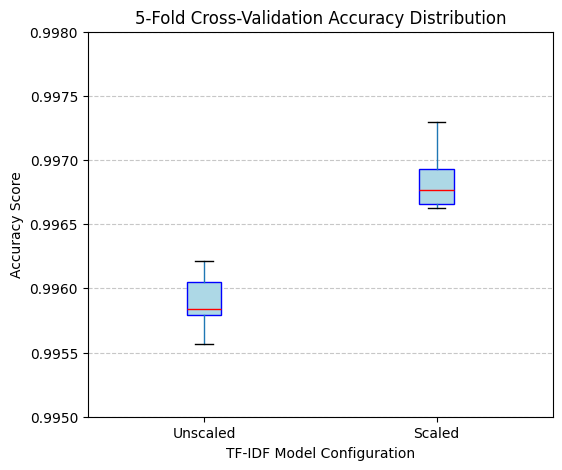

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

plot_data = {
    'Unscaled': [0.99605, 0.99579, 0.99584, 0.99557, 0.99621],
    'Scaled':   [0.99663, 0.99666, 0.99693, 0.99677, 0.99730]
}

df_plot = pd.DataFrame(plot_data)

plt.figure(figsize=(6, 5))
# create boxplot
df_plot.boxplot(column=['Unscaled', 'Scaled'], grid=False, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='blue'),
           medianprops=dict(color='red'))

plt.title('5-Fold Cross-Validation Accuracy Distribution')
plt.ylabel('Accuracy Score')
plt.xlabel('TF-IDF Model Configuration')
plt.ylim(0.9950, 0.9980) # Zoom in to see the gap
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.savefig('kfold_boxplot.png', dpi=300)
plt.show()

In [33]:
# evaluation on PhishOFE dataset

# lowercase all URLs from PhiUSIIL data
phiusiil_urls = set(data['URL'].dropna().astype(str).str.lower())

# boolean mask to check if PhishOFE entry exists in PhiUSIIL
overlap_mask = phishofe_data['URL'].astype(str).str.lower().apply(lambda x: x in phiusiil_urls)

# remove overlapping rows
phishofe_data_clean = phishofe_data[~overlap_mask].copy()

# assign X and y
X_phishofe_clean = phishofe_data_clean['URL']
y_phishofe_clean = phishofe_data_clean['label']

print(f"Original PhishOFE size: {len(phishofe_data):,}")
print(f"Cleaned PhishOFE size:  {len(phishofe_data_clean):,}")
print(f"Removed {len(phishofe_data) - len(phishofe_data_clean):,} overlapping URLs.")
print("-" * 35)

# re-evaluate on cleaned PhishOFE

print("\nEvaluating Unscaled Model on Cleaned Data...")
evaluate_model(pipe_char_no_scale, X_phishofe_clean, y_phishofe_clean)

print("\nEvaluating Scaled Model on Cleaned Data...")
evaluate_model(pipe_char, X_phishofe_clean, y_phishofe_clean)

Original PhishOFE size: 101,063
Cleaned PhishOFE size:  90,980
Removed 10,083 overlapping URLs.
-----------------------------------

Evaluating Unscaled Model on Cleaned Data...
Accuracy:  0.9969
Precision: 0.9997
Recall:    0.9941
F1 Score:  0.9969
------------------------------

Evaluating Scaled Model on Cleaned Data...
Accuracy:  0.9963
Precision: 0.9978
Recall:    0.9949
F1 Score:  0.9964
------------------------------


Dataset including derived and webpage scores (excluding URL Similarity Index)

In [34]:
columns_to_drop_web = ['label', 'URL', 'Domain', 'TLD', 'Title', 'URLSimilarityIndex']

y_all = data['label']
X_all = data.drop(columns=columns_to_drop_web)

# test size = 0.2
test_size_requested = 0.2
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X_all, y_all, test_size=test_size_requested, random_state=35)

Logistic regression including derived and webpage Scores (excluding URL Similarity Index)

In [35]:
# logistic regression

# max_iter=5000
lr_all = LogisticRegression(max_iter=5000)

lr_all_pipe = Pipeline([('scaler', StandardScaler()), ('lr', lr_all)])
lr_all_pipe.fit(X_train_all, y_train_all)
y_all_pred_lr = lr_all_pipe.predict(X_test_all)

print("accuracy score = ", lr_all_pipe.score(X_test_all, y_test_all))

evaluate_model(lr_all_pipe, X_test_all, y_test_all)

accuracy score =  0.999215420174304
Accuracy:  0.9992
Precision: 0.9994
Recall:    0.9988
F1 Score:  0.9991
------------------------------


In [36]:
run_kfold_cv(X_train_all, y_train_all, lr_all_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99923 | Prec = 0.99969 | Rec = 0.99852 | F1 = 0.99910
Fold 2: Acc = 0.99902 | Prec = 0.99888 | Rec = 0.99882 | F1 = 0.99885
Fold 3: Acc = 0.99939 | Prec = 0.99957 | Rec = 0.99901 | F1 = 0.99929
Fold 4: Acc = 0.99936 | Prec = 0.99938 | Rec = 0.99913 | F1 = 0.99926
Fold 5: Acc = 0.99934 | Prec = 0.99957 | Rec = 0.99889 | F1 = 0.99923
--------------------------------------------------
Average Accuracy:  0.99927
Average Precision: 0.99942
Average Recall:    0.99887
Average F1-Score:  0.99915
Best Validation Accuracy: 0.99939


(Pipeline(steps=[('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=5000))]),
 [0.9992313401187447,
  0.9990192700188194,
  0.9993903570387256,
  0.999363850823018,
  0.9993373446073104])

In [37]:
# random forest

# n=100
rf_all = RandomForestClassifier(n_estimators=100)

rf_all_pipe = Pipeline([('rf', rf_all)])
rf_all_pipe.fit(X_train_all, y_train_all)
y_all_pred_rf = rf_all_pipe.predict(X_test_all)

accuracy = accuracy_score(y_test_all, y_all_pred_rf)

print("accuracy score = ", accuracy)

evaluate_model(rf_all_pipe, X_test_all, y_test_all)

accuracy score =  0.9997879513984606
Accuracy:  0.9998
Precision: 1.0000
Recall:    0.9996
F1 Score:  0.9998
------------------------------


In [38]:
best_rf_all, acc_rf_all = run_kfold_cv(X_train_all, y_train_all, rf_all_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99989 | Prec = 0.99988 | Rec = 0.99988 | F1 = 0.99988
Fold 2: Acc = 0.99992 | Prec = 0.99988 | Rec = 0.99994 | F1 = 0.99991
Fold 3: Acc = 0.99995 | Prec = 1.00000 | Rec = 0.99988 | F1 = 0.99994
Fold 4: Acc = 0.99981 | Prec = 1.00000 | Rec = 0.99957 | F1 = 0.99978
Fold 5: Acc = 0.99984 | Prec = 0.99994 | Rec = 0.99969 | F1 = 0.99981
--------------------------------------------------
Average Accuracy:  0.99988
Average Precision: 0.99994
Average Recall:    0.99979
Average F1-Score:  0.99986
Best Validation Accuracy: 0.99995


In [39]:
# wilconox test between RF (W/ webpage scores) and LR (W/ derived and webpage scores)

compare_models_wilcoxon(
    acc_rf_web,
    acc_rf_all,
    model_a_name="RF (URL + HTML)",
    model_b_name="RF (All Features)"
)


--- Wilcoxon Signed-Rank Test: RF (URL + HTML) vs RF (All Features) ---
Wilcoxon Statistic: 0.0000
P-value: 0.50000
Result: NO statistically significant difference (Fail to reject H0).
Conclusion: The performance difference is likely due to random chance.


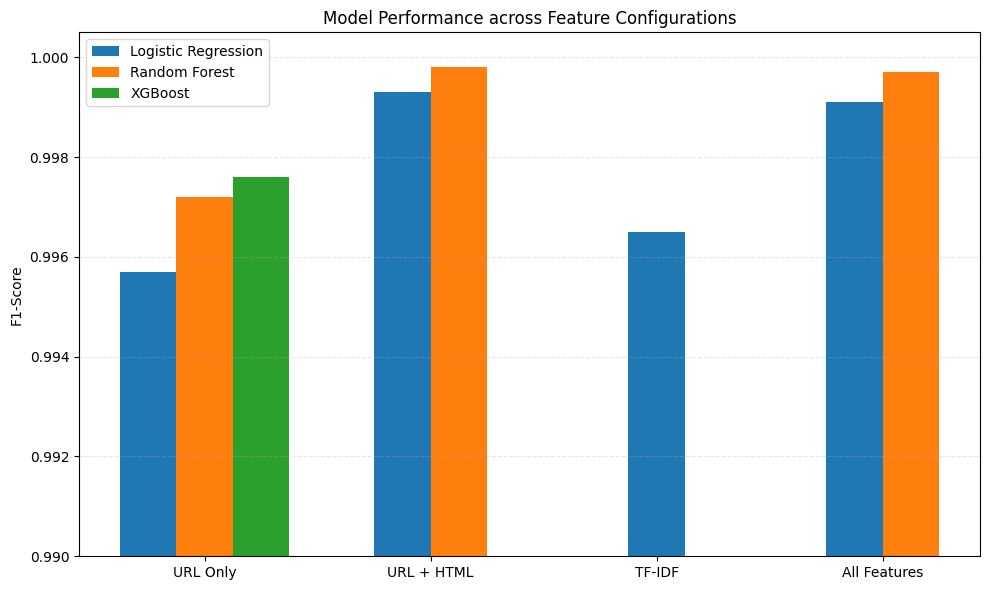

In [40]:
# plot all results in a bar graph

configs = ['URL Only', 'URL + HTML', 'TF-IDF', 'All Features']
lr_scores = [0.9957, 0.9993, 0.9965, 0.9991]
rf_scores = [0.9972, 0.9998, 0.0000, 0.9997]
xgb_scores = [0.9976, 0.0000, 0.0000, 0.0000]

models = [
    {'name': 'Logistic Regression', 'scores': lr_scores, 'color': '#1f77b4'},
    {'name': 'Random Forest', 'scores': rf_scores, 'color': '#ff7f0e'},
    {'name': 'XGBoost', 'scores': xgb_scores, 'color': '#2ca02c'}
]

x = np.arange(len(configs))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

added_labels = set()

for i in x:
    valid_bars = []
    for model in models:
        score = model['scores'][i]
        if score > 0:
            valid_bars.append({'score': score, 'color': model['color'], 'name': model['name']})

    n_bars = len(valid_bars)
    if n_bars == 0:
        continue

    # offset to center bars

    for j, bar_data in enumerate(valid_bars):
        offset = (j - (n_bars - 1) / 2) * width

        label = bar_data['name'] if bar_data['name'] not in added_labels else None
        if label:
            added_labels.add(label)

        ax.bar(i + offset, bar_data['score'], width, label=label, color=bar_data['color'])

ax.set_ylabel('F1-Score')
ax.set_title('Model Performance across Feature Configurations')
ax.set_xticks(x)
ax.set_xticklabels(configs)
ax.set_ylim(0.99, 1.0005)
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison_centered.png', dpi=300)
plt.show()

Qualitative Analysis of RF (URL + HTML)

In [41]:
def get_false_negatives(model, X_test, y_test, original_data, model_name="Model"):
    """
    Identifies False Negatives (Actual=1, Predicted=0) and retrieves
    the original URL and features for qualitative analysis.
    """
    # get predictions
    y_pred = model.predict(X_test)

    # convert y_test to series
    if not isinstance(y_test, pd.Series):
        y_test = pd.Series(y_test)

    # find indices where actual is 1 but predicted is 0
    fn_indices = y_test.index[(y_test == 1) & (y_pred == 0)]

    # retrieve the rows from the original dataset
    fn_data = original_data.loc[fn_indices]

    print(f"--- {model_name} ---")
    print(f"Total False Negatives: {len(fn_data)}")

    if len(fn_data) > 0:
        print("Sample False Negative URLs:")
        # display index and URL for easy lookup
        for idx, url in fn_data['URL'].head(5).items():
            print(f"Index {idx}: {url}")
        print("\n")
    else:
        print("Perfect recall (0 False Negatives).\n")

    return fn_data

In [42]:
# random forest (url + html)

get_false_negatives(rf_web_pipe, X_test_web, y_test_web, data, model_name="RF (W/ webpage scores)")

--- RF (W/ webpage scores) ---
Total False Negatives: 11
Sample False Negative URLs:
Index 76258: https://www.vmailmessage.com
Index 78962: https://www.tincanmonsters.com/
Index 112781: https://byil.blogspot.com/
Index 105405: https://www.interprocesoswebcancannovil.top/
Index 150614: https://pha.xujmno.xyz/logi/




,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
76258,https://www.vmailmessage.com,27,www.vmailmessage.com,20,0,com,61.856618,1.000000,0.522907,0.064095,...,0,0,1,1,1,0,0,0,0,1
78962,https://www.tincanmonsters.com/,31,www.tincanmonsters.com,22,0,com,82.456140,1.000000,0.522907,0.068492,...,1,0,1,8,2,3,0,0,0,1
112781,https://byil.blogspot.com/,26,byil.blogspot.com,17,0,com,75.500000,0.692308,0.522907,0.054252,...,0,0,1,4,3,3,3,0,13,1
105405,https://www.interprocesoswebcancannovil.top/,43,www.interprocesoswebcancannovil.top,35,0,top,52.237253,1.000000,0.000275,0.063316,...,0,0,1,2,5,7,14,0,18,1
150614,https://pha.xujmno.xyz/logi/,28,pha.xujmno.xyz,14,0,xyz,37.950139,0.700000,0.001750,0.040760,...,0,1,1,10,13,19,25,0,27,1
63616,https://www.alshayagropu.com/,29,www.alshayagropu.com,20,0,com,65.551711,1.000000,0.522907,0.057797,...,0,0,1,4,2,2,2,0,3,1
30066,https://www.connextsbridge.com/,30,www.connextsbridge.com,22,0,com,72.384665,1.000000,0.522907,0.060429,...,0,0,1,2,3,6,0,0,0,1
95625,https://www.seedjfly.top,24,www.seedjfly.top,16,0,top,73.183761,1.000000,0.000275,0.047648,...,0,0,0,4,4,7,0,0,1,1
58437,https://www.pencakefistaking.com/,32,www.pencakefistaking.com,24,0,com,59.428571,1.000000,0.522907,0.058114,...,0,1,0,2,3,7,0,0,0,1
28452,https://rariblies.blogspot.com/,30,rariblies.blogspot.com,22,0,com,70.819444,0.555556,0.522907,0.060719,...,1,0,1,3,3,3,9,0,32,1


In [43]:
def get_true_positives(model, X_test, y_test, original_data, model_name="Model"):
    """
    Identifies True Positives (Actual=1, Predicted=1) and retrieves
    the original URL and features for qualitative analysis.
    """
    # get predictions
    y_pred = model.predict(X_test)

    # convert y_test to series
    if not isinstance(y_test, pd.Series):
        y_test = pd.Series(y_test)

    # find indices where actual is 1 and predicted is 1
    tp_indices = y_test.index[(y_test == 1) & (y_pred == 1)]

    # retrieve the rows from the original dataset
    tp_data = original_data.loc[tp_indices]

    print(f"--- {model_name} ---")
    print(f"Total True Positives: {len(tp_data)}")

    if len(tp_data) > 0:
        print("Sample True Positive URLs (Correctly Detected):")
        # display index and URL for easy lookup
        for idx, url in tp_data['URL'].head(5).items():
            print(f"Index {idx}: {url}")
        print("\n")
    else:
        print("No True Positives found (0 detected).\n")

    return tp_data

In [44]:
# recall rate on HTTPS subset for RF (URL + HTML)

https_mask = X_test_web['IsHTTPS'] == 1

X_test_https = X_test_web[https_mask]
y_test_https = y_test_web[https_mask]

print(f"Total HTTPS websites in test set: {len(X_test_https)}")
print(f"Total HTTPS Phishing sites in test set: {y_test_https.sum()}") # 1=Phishing
print("-" * 30)

https_phishing_mask = y_test_https == 1
X_test_https_phishing = X_test_https[https_phishing_mask]
y_test_https_phishing = y_test_https[https_phishing_mask]

https_successes = get_true_positives(
    rf_web_pipe,
    X_test_https_phishing,
    y_test_https_phishing,
    data,
    model_name="RF (URL+HTML) - HTTPS Phishing Detection"
)

total_https_phish = len(y_test_https_phishing)
detected_https_phish = len(https_successes)

if total_https_phish > 0:
    recall_on_https = detected_https_phish / total_https_phish
    print(f"Summary: The model correctly identified {detected_https_phish} out of {total_https_phish} HTTPS phishing sites.")
    print(f"HTTPS Recall Rate: {recall_on_https:.2%}")
else:
    print("No HTTPS phishing sites found in the test set to analyze.")

Total HTTPS websites in test set: 36933
Total HTTPS Phishing sites in test set: 9893
------------------------------
--- RF (URL+HTML) - HTTPS Phishing Detection ---
Total True Positives: 9882
Sample True Positive URLs (Correctly Detected):
Index 102449: https://doncov.line.pm/
Index 111111: https://cloudflare-ipfs.com/ipfs/bafybeihxptow7hycar3aghbxd4xvws4sucyqh2tzgz3wvo7eoj4qkrgahy
Index 46152: https://szinv2.web.app/
Index 164597: https://heartfeltlightapplicationstack--promeriy.repl.co/
Index 176294: https://juriskiana11.firebaseapp.com/


Summary: The model correctly identified 9882 out of 9893 HTTPS phishing sites.
HTTPS Recall Rate: 99.89%


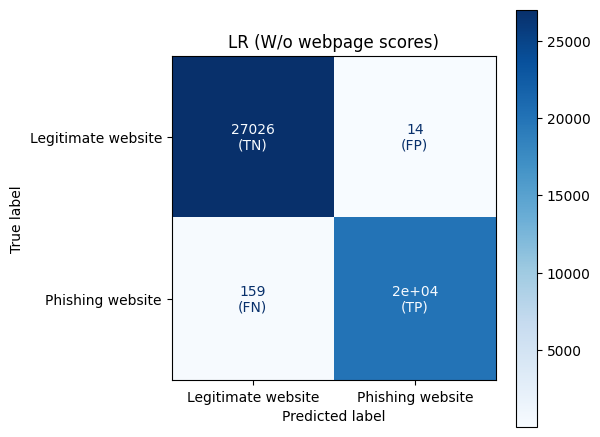

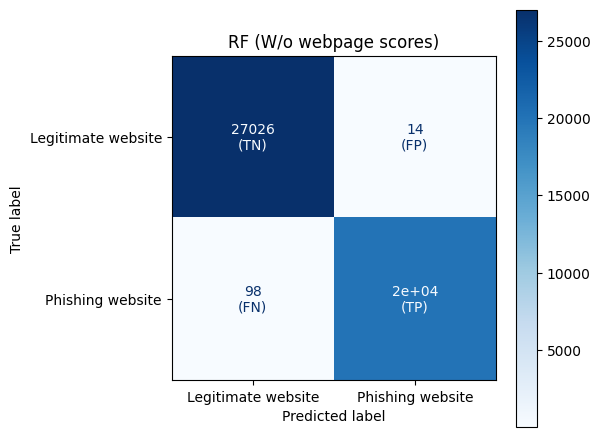

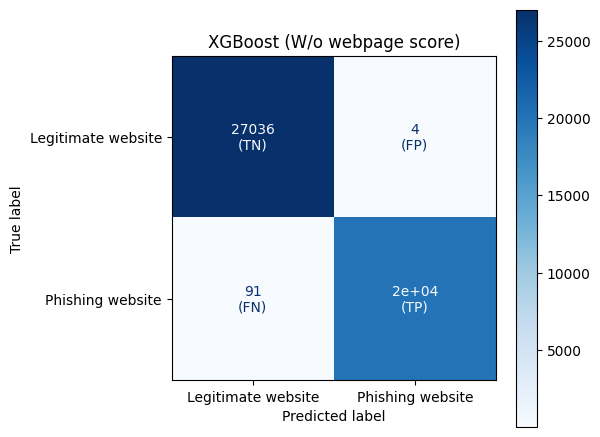

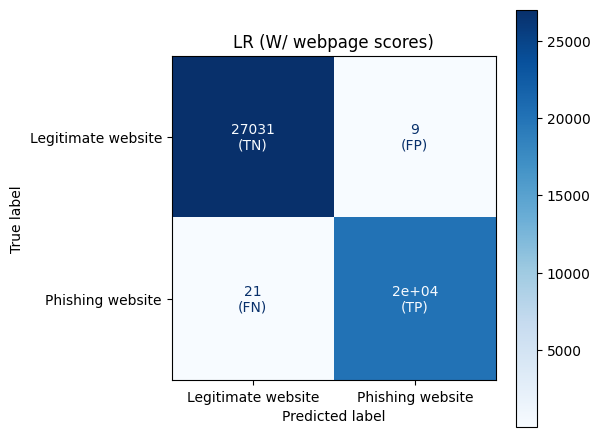

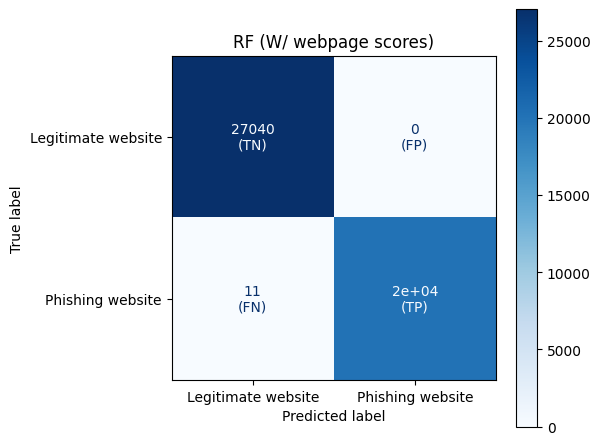

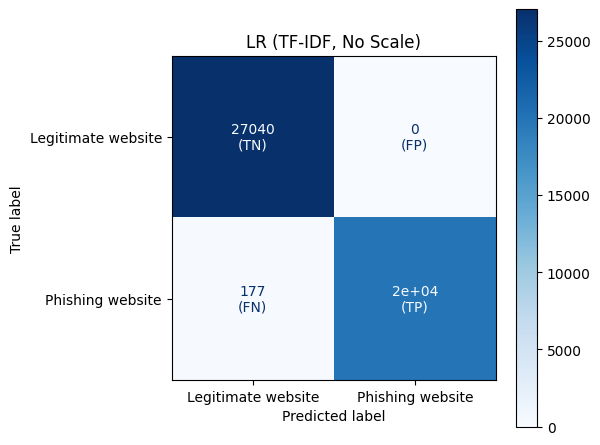

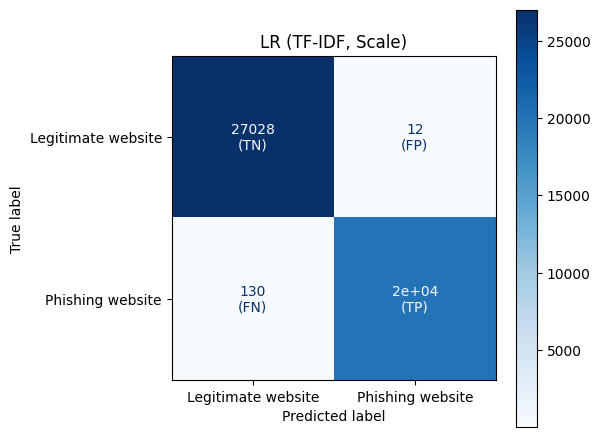

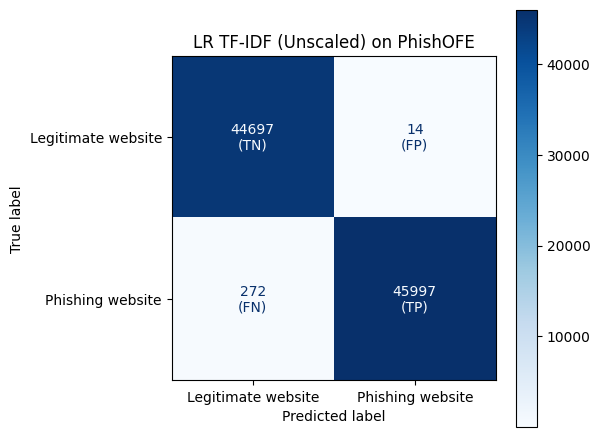

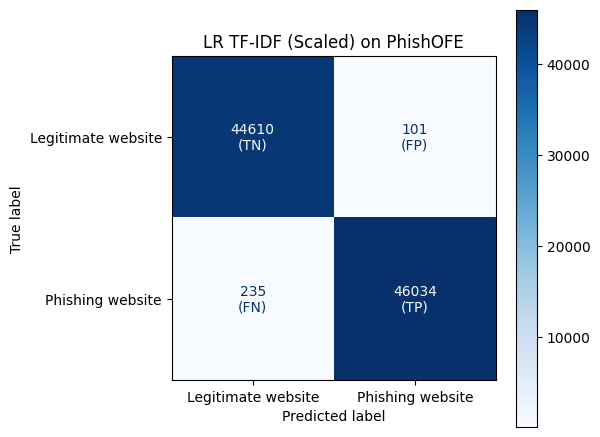

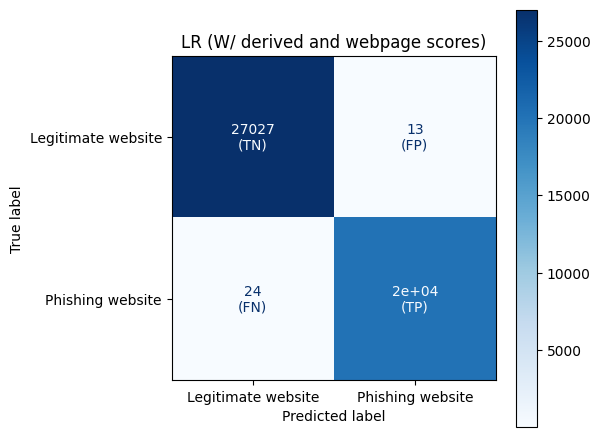

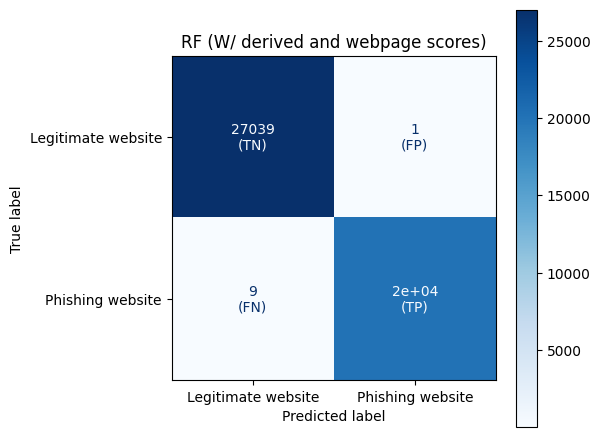

In [45]:
# confusion matrices

plot_confusion_matrix(lr_pipe, X_test_num, y_test_num, title="LR (W/o webpage scores)")
plot_confusion_matrix(rf_pipe, X_test_num, y_test_num, title="RF (W/o webpage scores)")
plot_confusion_matrix(xgb_pipe, X_test_num, y_test_num, title="XGBoost (W/o webpage score)")

plot_confusion_matrix(lr_web_pipe, X_test_web, y_test_web, title="LR (W/ webpage scores)")
plot_confusion_matrix(rf_web_pipe, X_test_web, y_test_web, title="RF (W/ webpage scores)")


plot_confusion_matrix(pipe_char_no_scale, X_test_url, y_test_url, title="LR (TF-IDF, No Scale)")
plot_confusion_matrix(pipe_char, X_test_url, y_test_url, title="LR (TF-IDF, Scale)")

plot_confusion_matrix(pipe_char_no_scale, X_phishofe_clean, y_phishofe_clean, title="LR TF-IDF (Unscaled) on PhishOFE")
plot_confusion_matrix(pipe_char, X_phishofe_clean, y_phishofe_clean, title="LR TF-IDF (Scaled) on PhishOFE")

plot_confusion_matrix(lr_all_pipe, X_test_all, y_test_all, title="LR (W/ derived and webpage scores)")
plot_confusion_matrix(rf_all_pipe, X_test_all, y_test_all, title="RF (W/ derived and webpage scores)")

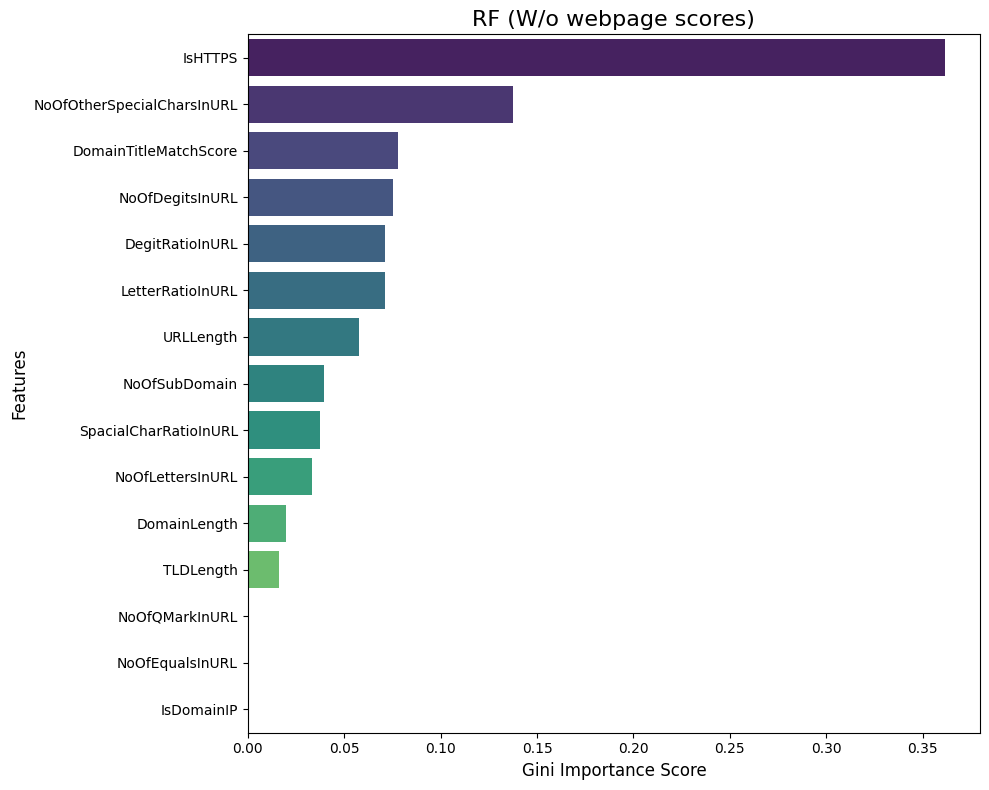

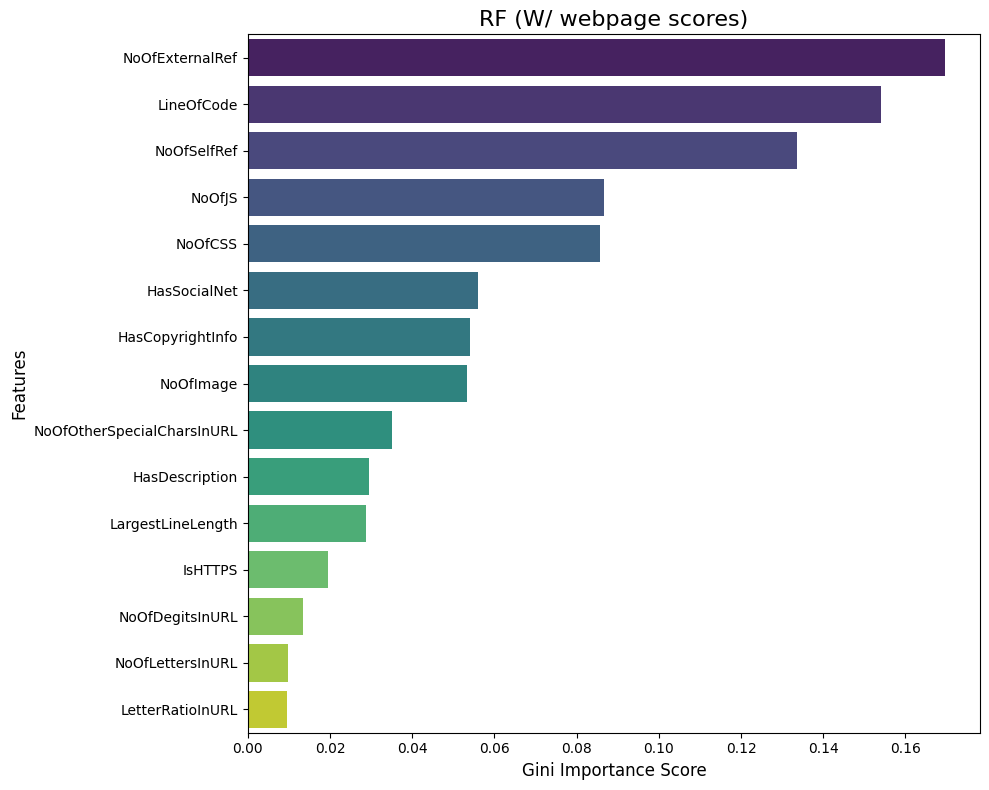

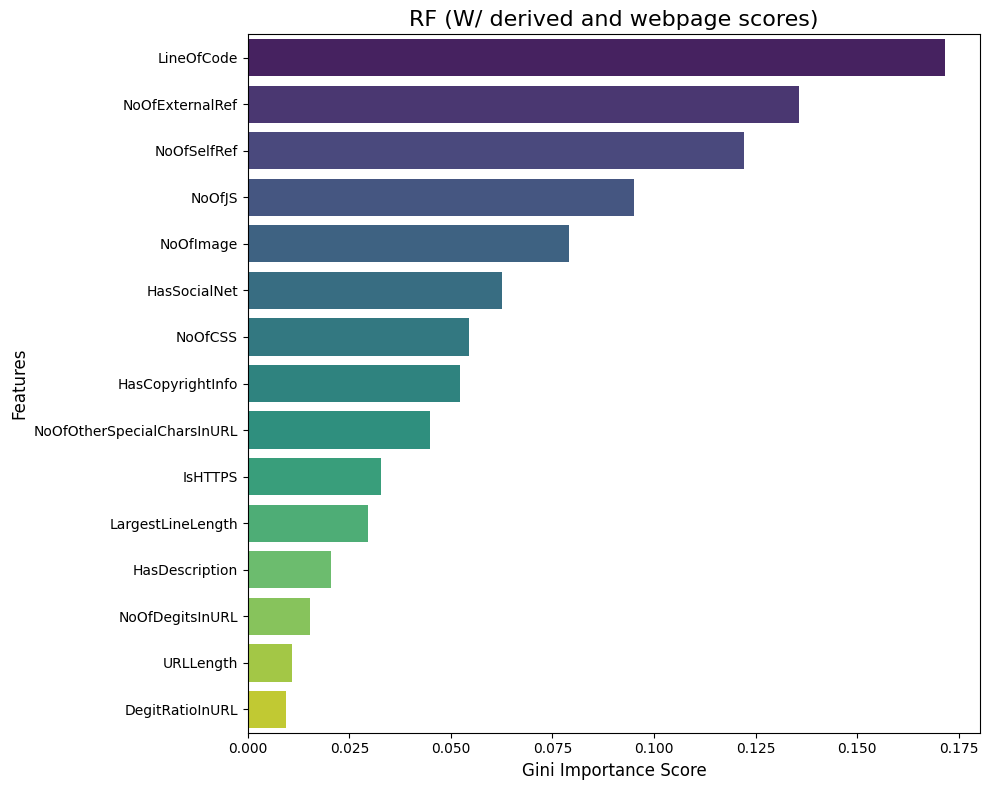

In [46]:
# RF feature importance graphs

plot_top_features(rf_pipe, X_train_num, title="RF (W/o webpage scores)")
plot_top_features(rf_web_pipe, X_train_web, title="RF (W/ webpage scores)")
plot_top_features(rf_all_pipe, X_train_all, title="RF (W/ derived and webpage scores)")